In [31]:
# Import thư viện
import sys
from pathlib import Path

# Thêm thư mục gốc project vào Python Path
project_dir = Path.cwd().parent
sys.path.append(str(project_dir))

# Import các hàm xử lý dữ liệu
from src.data_preprocessing import (
    load_data,
    select_features,
    scale_features
)

# Import các thuật toán phân cụm
from src.clustering import (
    run_kmeans,
    run_dbscan,
    run_hierarchical
)

# Import các hàm đánh giá
from src.evaluation import (
    calculate_inertia,
    calculate_silhouette
)

# Import các hàm trực quan hóa
from src.visualization import (
    plot_elbow,
    plot_clusters,
    plot_k_distance
)

print("Import modules successfully!")

Import modules successfully!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Các thư viện đã được import thành công!")

Các thư viện đã được import thành công!


# 1. DATA LOADING

Đọc bộ dữ liệu Mall Customers Dataset vào Python
để chuẩn bị cho quá trình khám phá và phân tích dữ liệu.

In [2]:
# Load dataset
df = load_data()

# Hiển thị dữ liệu
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [5]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



### Nhận xét kết quả thống kê mô tả

Tập dữ liệu Mall Customers gồm 200 khách hàng với 5 thuộc tính. Qua bảng thống kê mô tả, có thể nhận thấy:

- Độ tuổi khách hàng dao động từ 18 đến 70 tuổi, độ tuổi trung bình là 38.85.
- Thu nhập hằng năm dao động từ 15 đến 137 nghìn USD, trung bình đạt 60.56 nghìn USD.
- Spending Score dao động từ 1 đến 99, với giá trị trung bình là 50.2.
- Độ lệch chuẩn của các thuộc tính Age, Annual Income và Spending Score cho thấy dữ liệu có sự biến thiên giữa các khách hàng.


Cột CustomerID chỉ mang ý nghĩa định danh nên sẽ không được sử dụng làm đặc trưng đầu vào cho mô hình.


In [6]:
# Kiểm tra giá trị thiếu
print("Missing values:")
print(df.isnull().sum())

# Kiểm tra dữ liệu trùng lặp
print("\nDuplicate values:")
print(df.duplicated().sum())

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate values:
0



### Kiểm tra chất lượng dữ liệu

Sau khi kiểm tra dữ liệu, kết quả cho thấy:

- Không có giá trị thiếu (Missing Values) trong cả 5 thuộc tính.
- Không phát hiện dòng dữ liệu trùng lặp (Duplicate Values).
- Tập dữ liệu có đầy đủ 200 bản ghi.

**Kết luận:**

Bộ dữ liệu Mall Customers có chất lượng tương đối tốt và chưa cần thực hiện các bước xử lý giá trị thiếu hoặc dữ liệu trùng lặp. Nhóm có thể tiếp tục khám phá sự phân bố và mối quan hệ giữa các thuộc tính trước khi tiến hành tiền xử lý dữ liệu.


## 2. EXPLORATORY DATA ANALYSIS (EDA)

### 2.1. Gender Distribution

Phân tích số lượng và tỷ lệ khách hàng theo giới tính.

In [7]:
# Đếm số lượng khách hàng theo giới tính
gender_counts = df["Gender"].value_counts()

print(gender_counts)

Gender
Female    112
Male       88
Name: count, dtype: int64



### 2.1. Gender Distribution – Phân phối giới tính

Kết quả thống kê cho thấy tập dữ liệu có 112 khách hàng nữ (56%) và 88 khách hàng nam (44%).

Số lượng khách hàng nữ cao hơn khách hàng nam 24 người. Tuy nhiên, sự chênh lệch không quá lớn, cho thấy cơ cấu giới tính trong tập dữ liệu tương đối cân bằng.

Thông tin về giới tính có thể được sử dụng để hỗ trợ phân tích đặc điểm của từng nhóm khách hàng sau khi phân cụm.


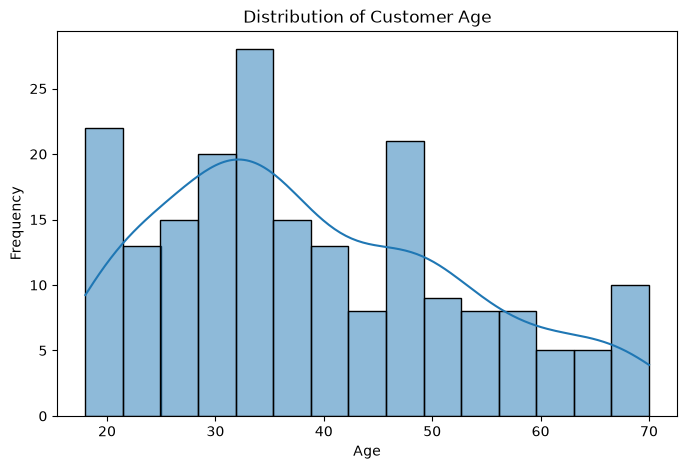

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=15, kde=True)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

### 2.2. Age Distribution – Phân phối độ tuổi

Biểu đồ cho thấy độ tuổi của khách hàng dao động từ 18 đến 70 tuổi. 
Trong đó, khách hàng tập trung nhiều nhất ở nhóm tuổi từ 30 đến 35.

Phần lớn khách hàng nằm trong khoảng 20 đến 40 tuổi. 
Sau độ tuổi 50, tần suất khách hàng nhìn chung có xu hướng giảm.

Điều này cho thấy tập dữ liệu có sự đa dạng về độ tuổi, 
nhưng nhóm khách hàng trẻ và trung niên chiếm tỷ lệ đáng kể. 
Đặc điểm độ tuổi có thể hỗ trợ việc phân tích và xác định 
các nhóm khách hàng có hành vi tiêu dùng khác nhau.

### 2.3. Annual Income Distribution

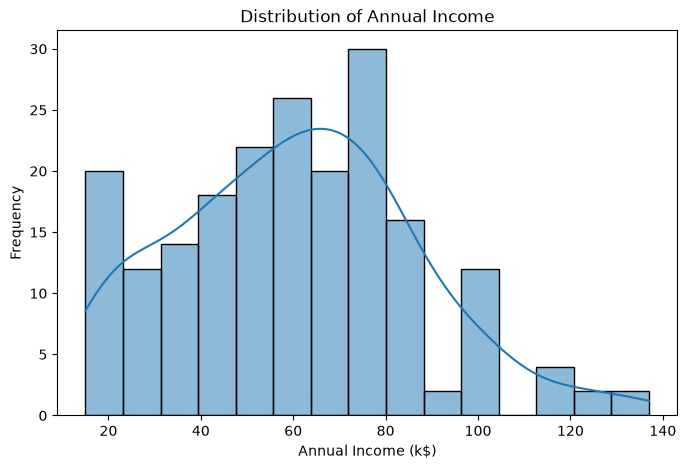

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Annual Income (k$)", bins=15, kde=True)

plt.title("Distribution of Annual Income")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Frequency")

plt.show()

### 2.3. Annual Income Distribution – Phân phối thu nhập hàng năm

Biểu đồ cho thấy thu nhập hàng năm của khách hàng dao động 
từ khoảng 15 đến 137 nghìn USD.

Phần lớn khách hàng có mức thu nhập trong khoảng 50–85 nghìn USD, 
trong đó nhóm 70–80 nghìn USD có tần suất xuất hiện cao nhất.

Ngoài ra, số lượng khách hàng có thu nhập trên 100 nghìn USD 
không nhiều. Phân phối có xu hướng lệch phải do phần đuôi 
kéo dài về phía các mức thu nhập cao.

Điều này cho thấy mức thu nhập giữa các khách hàng có sự 
khác biệt. Đây là một đặc trưng có thể hỗ trợ quá trình 
phân cụm và phân tích hành vi tiêu dùng.

### 2.4. Spending Score Distribution

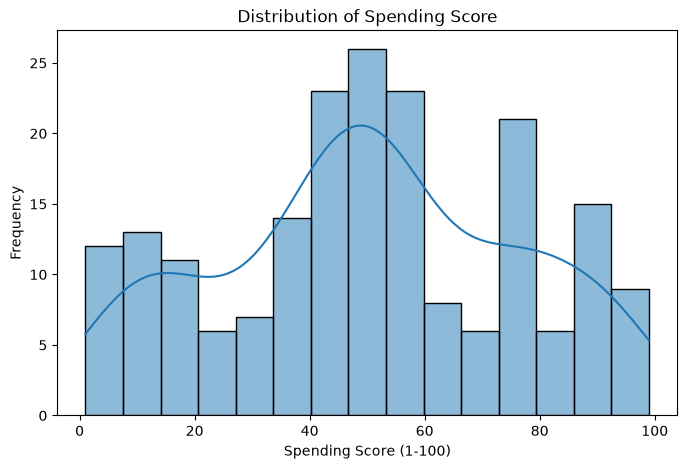

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Spending Score (1-100)", bins=15, kde=True)

plt.title("Distribution of Spending Score")
plt.xlabel("Spending Score (1-100)")
plt.ylabel("Frequency")

plt.show()

### 2.4. Spending Score Distribution – Phân phối điểm chi tiêu

Biểu đồ cho thấy điểm chi tiêu của khách hàng dao động từ 1 đến 99.

Phần lớn khách hàng có điểm chi tiêu trong khoảng 40–60, 
trong đó nhóm 45–55 có tần suất xuất hiện cao nhất.

Ngoài ra, dữ liệu cũng có một số nhóm khách hàng đạt điểm 
chi tiêu thấp (dưới 20) và điểm chi tiêu cao (từ 70 trở lên).

Điều này cho thấy hành vi chi tiêu giữa các khách hàng có 
sự khác biệt đáng kể. Đây là một đặc trưng quan trọng 
trong bài toán phân khúc khách hàng.

### 2.5. Annual Income vs Spending Score

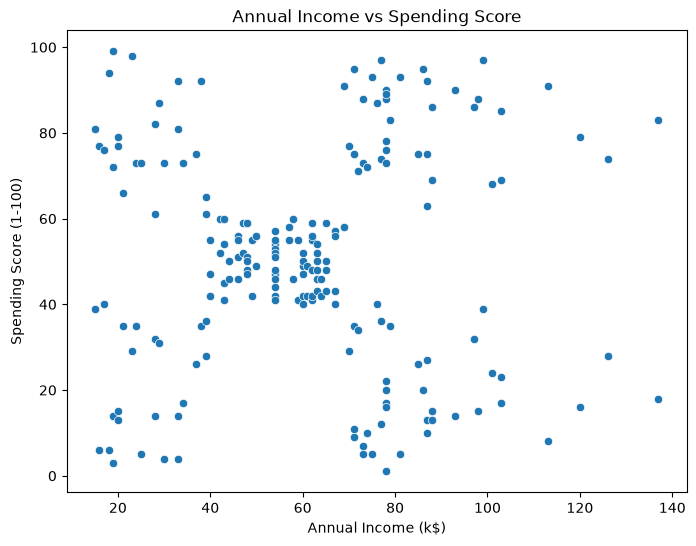

In [11]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)"
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")

plt.show()

### 2.6. Age vs Spending Score

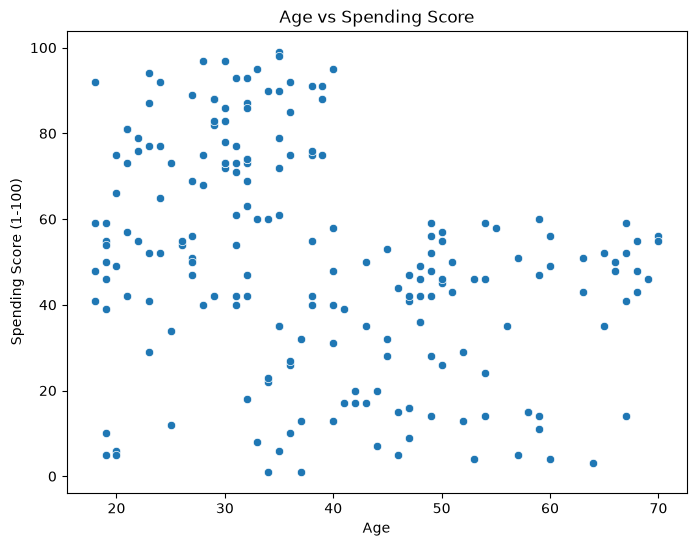

In [12]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Spending Score (1-100)"
)

plt.title("Age vs Spending Score")
plt.xlabel("Age")
plt.ylabel("Spending Score (1-100)")

plt.show()

### 2.6. Age vs Spending Score – Mối quan hệ giữa độ tuổi và điểm chi tiêu

Biểu đồ Scatter Plot thể hiện mối quan hệ giữa độ tuổi và điểm 
chi tiêu của khách hàng.

Có thể nhận thấy khách hàng trẻ (18–40 tuổi) có điểm chi tiêu 
phân bố khá rộng, trong đó có nhiều khách hàng đạt điểm cao.

Đối với nhóm khách hàng trên 40 tuổi, điểm chi tiêu chủ yếu 
tập trung trong khoảng 35–60, tuy nhiên vẫn tồn tại một số 
khách hàng có điểm chi tiêu thấp.

Nhìn chung, không có mối quan hệ tuyến tính rõ ràng giữa 
độ tuổi và điểm chi tiêu. Những khách hàng cùng độ tuổi 
có thể có hành vi chi tiêu khác nhau.

Điều này cho thấy độ tuổi là một đặc trưng có thể hỗ trợ 
phân tích khách hàng, nhưng cần kết hợp với thu nhập và 
điểm chi tiêu để phân nhóm hiệu quả hơn.

## 3. DATA PREPROCESSING
### 3.1. Feature Selection

In [3]:
# Select features
X = select_features(df)

# Scale features
X_scaled, scaler = scale_features(X)

print("Original features shape:", X.shape)
print("Scaled features shape:", X_scaled.shape)

X_scaled.head()

Original features shape: (200, 2)
Scaled features shape: (200, 2)


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


### 3.2. Feature Scaling – Chuẩn hóa dữ liệu

In [26]:
# Scale features
X_scaled, scaler = scale_features(X)

print("Scaled features shape:", X_scaled.shape)
X_scaled.head()

Scaled features shape: (200, 2)


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


### 3.2. Feature Scaling – Chuẩn hóa dữ liệu

Sau khi lựa chọn hai đặc trưng Annual Income và Spending Score, 
tiến hành chuẩn hóa dữ liệu bằng phương pháp StandardScaler.

Phương pháp này đưa các đặc trưng về cùng thang đo, 
giúp hạn chế ảnh hưởng của sự khác biệt về đơn vị 
và độ lớn giá trị khi tính toán khoảng cách.

Sau khi chuẩn hóa, các đặc trưng có giá trị trung bình 
xấp xỉ 0 và độ lệch chuẩn xấp xỉ 1.

Kết quả này giúp dữ liệu phù hợp hơn cho quá trình 
xây dựng các mô hình phân cụm.

In [27]:
# Kiểm tra giá trị trung bình
print("Mean:")
print(X_scaled.mean())

# Kiểm tra độ lệch chuẩn
print("\nStandard Deviation:")
print(X_scaled.std())

Mean:
Annual Income (k$)       -2.131628e-16
Spending Score (1-100)   -1.465494e-16
dtype: float64

Standard Deviation:
Annual Income (k$)        1.002509
Spending Score (1-100)    1.002509
dtype: float64


### 3.3. Kiểm tra dữ liệu sau chuẩn hóa

Sau khi sử dụng StandardScaler, tiến hành kiểm tra giá trị 
trung bình (Mean) và độ lệch chuẩn (Standard Deviation) 
của các đặc trưng.

Kết quả cho thấy:
- Mean của hai đặc trưng xấp xỉ bằng 0.
- Standard Deviation của hai đặc trưng xấp xỉ bằng 1.

Như vậy, quá trình chuẩn hóa dữ liệu đã được thực hiện 
thành công. Dữ liệu sẵn sàng cho bước xây dựng mô hình 
phân cụm.

## 4. MODEL BUILDING
### 4.1. K-Means Clustering
#### 4.1.1. Finding Optimal K – Elbow Method

In [28]:
# Tính Inertia với số cụm từ 1 đến 10
inertia_values = calculate_inertia(
    X_scaled,
    max_k=10
)

print(inertia_values)

[400.0, 269.6910121927639, 157.70400815035947, 108.92131661364355, 65.56840815571681, 55.057348270385994, 44.86475569922557, 37.228187677585886, 32.39226763033116, 29.981897788243693]


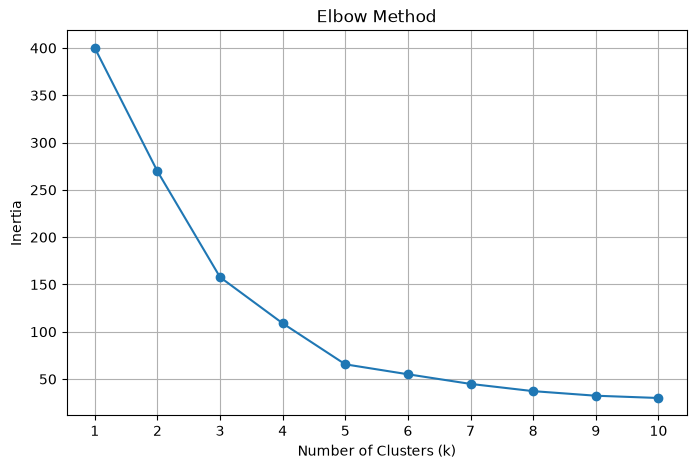

In [29]:
# Vẽ biểu đồ Elbow Method
plot_elbow(
    inertia_values,
    save_path="../results/figures/elbow_method.png"
)

#### 4.1.1. Finding Optimal K – Elbow Method

Sử dụng phương pháp Elbow để xác định số cụm K phù hợp 
cho thuật toán K-Means.

Thử nghiệm các giá trị K từ 1 đến 10 và tính toán Inertia 
tương ứng.

Kết quả cho thấy Inertia giảm mạnh khi K tăng từ 1 đến 5. 
Từ K = 5 trở đi, tốc độ giảm Inertia chậm hơn và đường 
cong bắt đầu thoải.

Vì vậy, lựa chọn K = 5 làm số cụm đề xuất ban đầu 
cho mô hình K-Means.

Số cụm này sẽ được kiểm tra thêm bằng Silhouette Score.

In [4]:
# Chạy mô hình K-Means với 5 cụm
kmeans, y_kmeans = run_kmeans(
    X_scaled,
    n_clusters=5
)

# Gán nhãn cụm vào DataFrame ban đầu
df["Cluster"] = y_kmeans

# Hiển thị kết quả
df[["Annual Income (k$)", "Spending Score (1-100)", "Cluster"]].head()

,Annual Income (k$),Spending Score (1-100),Cluster
0,15,39,4
1,15,81,2
2,16,6,4
3,16,77,2
4,17,40,4


#### 4.1.2. Training K-Means Model

Sau khi xác định K = 5 bằng Elbow Method, tiến hành 
xây dựng mô hình K-Means với 5 cụm.

Sử dụng phương thức fit_predict() để huấn luyện mô hình 
và gán nhãn cụm cho từng khách hàng.

Kết quả cho thấy mỗi khách hàng được phân vào một trong 
5 cụm, có nhãn từ 0 đến 4.

Các khách hàng có đặc điểm thu nhập và điểm chi tiêu 
tương đồng có xu hướng được xếp vào cùng một cụm.

In [19]:
# Đếm số lượng khách hàng trong từng cụm
cluster_counts = df["Cluster"].value_counts().sort_index()

print("Số lượng khách hàng trong từng cụm:")
print(cluster_counts)

Số lượng khách hàng trong từng cụm:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


#### 4.1.3. Cluster Distribution – Phân bố số lượng khách hàng

Sau khi huấn luyện mô hình K-Means với K = 5, 
200 khách hàng được phân chia thành 5 cụm.

Kết quả:
- Cluster 0: 81 khách hàng (40.5%).
- Cluster 1: 39 khách hàng (19.5%).
- Cluster 2: 22 khách hàng (11%).
- Cluster 3: 35 khách hàng (17.5%).
- Cluster 4: 23 khách hàng (11.5%).

Cluster 0 có số lượng khách hàng lớn nhất, chiếm 40.5% 
tổng số khách hàng. Trong khi đó, Cluster 2 có số lượng 
khách hàng ít nhất, chiếm 11%.

Kết quả cho thấy quy mô các nhóm khách hàng không đồng đều.

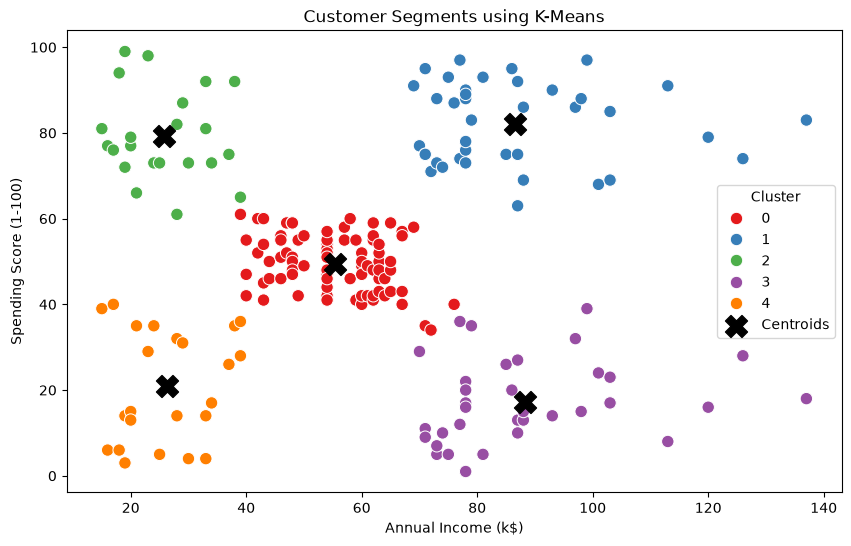

In [20]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set1",
    s=80
)

# Hiển thị tâm cụm
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    c="black",
    label="Centroids"
)

plt.title("Customer Segments using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()

#### 4.1.4. K-Means Clustering Visualization

Sau khi huấn luyện mô hình K-Means với K = 5, tiến hành 
trực quan hóa kết quả phân cụm bằng biểu đồ Scatter Plot.

Kết quả cho thấy 200 khách hàng được chia thành 5 nhóm 
dựa trên hai đặc trưng Annual Income và Spending Score.

Đặc điểm của từng cụm:
- Cluster 0: Khách hàng có thu nhập và điểm chi tiêu trung bình.
- Cluster 1: Khách hàng có thu nhập cao và điểm chi tiêu cao.
- Cluster 2: Khách hàng có thu nhập thấp nhưng điểm chi tiêu cao.
- Cluster 3: Khách hàng có thu nhập cao nhưng điểm chi tiêu thấp.
- Cluster 4: Khách hàng có thu nhập thấp và điểm chi tiêu thấp.

Các dấu X màu đen trên biểu đồ biểu thị Centroids 
(tâm cụm), đại diện cho vị trí trung tâm của từng nhóm.

Nhìn chung, mô hình đã phân chia dữ liệu thành các nhóm 
có đặc điểm thu nhập và hành vi chi tiêu khác nhau. 
Kết quả có thể hỗ trợ doanh nghiệp nhận diện các phân khúc 
khách hàng để xây dựng chiến lược tiếp thị phù hợp.

In [5]:
# Tính Silhouette Score
silhouette_avg = calculate_silhouette(X_scaled, y_kmeans)

print("Silhouette Score:", silhouette_avg)

Silhouette Score: 0.5546571631111091


#### 4.1.5. Model Evaluation – Silhouette Score

Sử dụng Silhouette Score để đánh giá chất lượng phân cụm 
của mô hình K-Means với K = 5.

Kết quả thu được:

Silhouette Score = 0.5547

Giá trị này cho thấy các cụm có độ gắn kết và khả năng 
tách biệt tương đối tốt. Phần lớn khách hàng được phân 
vào các cụm phù hợp, mặc dù vẫn có thể tồn tại một số 
điểm dữ liệu nằm gần ranh giới giữa các cụm.

Nhìn chung, mô hình K-Means với K = 5 đạt kết quả 
phân cụm tương đối tốt trên tập dữ liệu đang sử dụng.

In [30]:
import importlib
import src.visualization

importlib.reload(src.visualization)

print(hasattr(src.visualization, "plot_k_distance"))

True


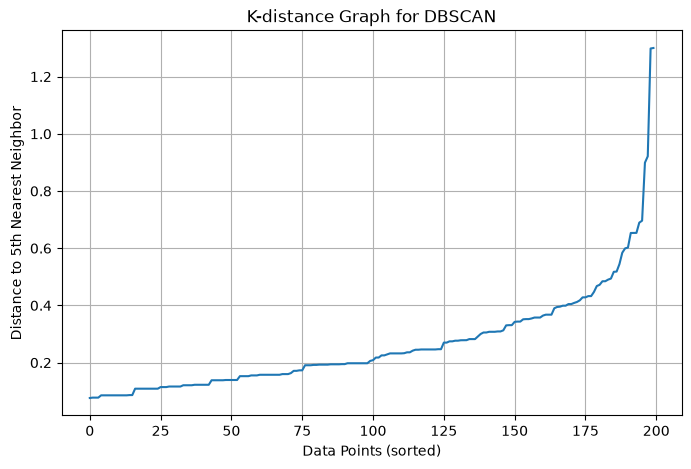

In [39]:
# Vẽ và lưu biểu đồ K-distance
plot_k_distance(
    X_scaled,
    n_neighbors=5,
    save_path="../results/figures/k_distance.png"
)

#### 4.2.1. Parameter Selection – Lựa chọn tham số DBSCAN

Sử dụng biểu đồ K-distance để hỗ trợ lựa chọn tham số 
eps cho thuật toán DBSCAN.

Biểu đồ thể hiện khoảng cách từ mỗi điểm dữ liệu đến 
điểm láng giềng thứ 5 sau khi sắp xếp khoảng cách tăng dần.

Quan sát biểu đồ, phần lớn các điểm có khoảng cách 
tăng tương đối chậm. Tuy nhiên, ở đoạn cuối đường cong, 
khoảng cách bắt đầu tăng nhanh.

Vùng gấp khúc được ước lượng nằm trong khoảng 0.5–0.6. 
Do đó, lựa chọn eps = 0.5 và min_samples = 5 
làm bộ tham số ban đầu để thử nghiệm DBSCAN.

Các tham số này sẽ được đánh giá thông qua kết quả 
phân cụm thực tế.

#### 4.2.2. Training DBSCAN Model

In [9]:
# Chạy mô hình DBSCAN
dbscan, y_dbscan = run_dbscan(
    X_scaled,
    eps=0.5,
    min_samples=5
)

# Lưu nhãn cụm vào DataFrame
df["DBSCAN_Cluster"] = y_dbscan

# Hiển thị kết quả
df[["Annual Income (k$)",
    "Spending Score (1-100)",
    "DBSCAN_Cluster"]].head()

,Annual Income (k$),Spending Score (1-100),DBSCAN_Cluster
0,15,39,0
1,15,81,0
2,16,6,0
3,16,77,0
4,17,40,0


In [25]:
# Đếm số lượng khách hàng trong từng cụm
dbscan_counts = df["DBSCAN_Cluster"].value_counts().sort_index()

print("Số lượng khách hàng trong từng cụm DBSCAN:")
print(dbscan_counts)

Số lượng khách hàng trong từng cụm DBSCAN:
DBSCAN_Cluster
-1      8
 0    157
 1     35
Name: count, dtype: int64


#### 4.2.3. Cluster Distribution – Phân bố cụm DBSCAN

Sau khi sử dụng DBSCAN với eps = 0.5 và min_samples = 5,
mô hình thu được kết quả gồm 2 cụm và 8 điểm nhiễu.

Cụ thể:
- Cluster 0: 157 khách hàng (78.5%).
- Cluster 1: 35 khách hàng (17.5%).
- Noise (-1): 8 khách hàng (4%).

Cluster 0 chiếm phần lớn dữ liệu, trong khi Cluster 1
có quy mô nhỏ hơn. Ngoài ra, mô hình phát hiện 8 điểm
nhiễu không thuộc cụm nào.

Kết quả cho thấy DBSCAN có khả năng phát hiện các điểm
nhiễu dựa trên mật độ dữ liệu. Tuy nhiên, với bộ tham số
hiện tại, dữ liệu chủ yếu được chia thành hai cụm lớn.

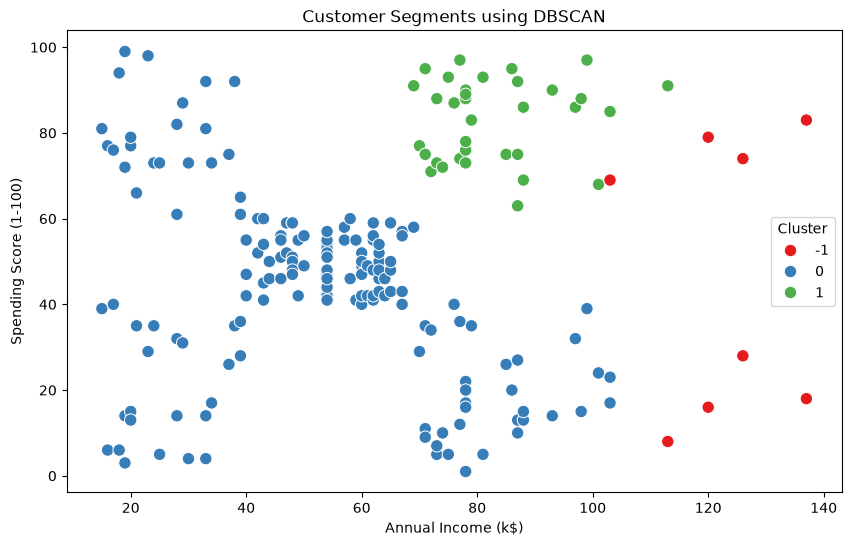

In [37]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="DBSCAN_Cluster",
    palette="Set1",
    s=80
)

plt.title("Customer Segments using DBSCAN")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")

plt.savefig(
    "../results/figures/dbscan_segments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 4.2.4. DBSCAN Clustering Visualization

Sau khi huấn luyện mô hình DBSCAN với eps = 0.5 và 
min_samples = 5, tiến hành trực quan hóa kết quả 
phân cụm bằng biểu đồ Scatter Plot.

Kết quả cho thấy mô hình tạo ra 2 cụm và phát hiện 
8 điểm nhiễu.

Đặc điểm quan sát được:
- Cluster 0: Cụm lớn, chứa phần lớn khách hàng với 
  nhiều vùng phân bố khác nhau.
- Cluster 1: Tập trung chủ yếu ở vùng thu nhập và 
  điểm chi tiêu cao.
- Noise (-1): Các điểm dữ liệu không đáp ứng điều kiện 
  mật độ để được xếp vào cụm.

Các điểm nhiễu được đánh dấu bằng màu đỏ trên biểu đồ.

Nhìn chung, DBSCAN có khả năng phát hiện dữ liệu nhiễu, 
nhưng với bộ tham số hiện tại, mô hình chỉ tạo ra 
hai cụm và chưa phân chia rõ các nhóm khách hàng 
như kết quả K-Means.

#### 4.2.5. Model Evaluation – Silhouette Score

In [10]:
# Tính Silhouette Score cho DBSCAN
silhouette_dbscan = calculate_silhouette(
    X_scaled,
    y_dbscan
)

if silhouette_dbscan is not None:
    print("Silhouette Score (DBSCAN):", silhouette_dbscan)
else:
    print("Không đủ số cụm để tính Silhouette Score.")

Silhouette Score (DBSCAN): 0.3875583892728279


#### 4.2.5. Model Evaluation – Silhouette Score

Sử dụng Silhouette Score để đánh giá chất lượng phân cụm 
của mô hình DBSCAN.

Với eps = 0.5 và min_samples = 5, kết quả thu được:

Silhouette Score = 0.3876

Chỉ số được tính trên 192 khách hàng không thuộc nhóm 
Noise, sau khi loại bỏ 8 điểm nhiễu.

Kết quả cho thấy các cụm có mức độ gắn kết và tách biệt 
nhất định, tuy nhiên chất lượng phân cụm chưa cao.

DBSCAN có ưu điểm là phát hiện được các điểm nhiễu, 
nhưng với bộ tham số hiện tại, mô hình chỉ tạo ra 
2 cụm khách hàng.

## 4.3. HIERARCHICAL CLUSTERING
### 4.3.1. Training Hierarchical Clustering Model

In [11]:
# Chạy mô hình Hierarchical Clustering
hierarchical, y_hierarchical = run_hierarchical(
    X_scaled,
    n_clusters=5
)

# Lưu nhãn cụm vào DataFrame
df["Hierarchical_Cluster"] = y_hierarchical

# Hiển thị kết quả
df[[
    "Annual Income (k$)",
    "Spending Score (1-100)",
    "Hierarchical_Cluster"
]].head()

,Annual Income (k$),Spending Score (1-100),Hierarchical_Cluster
0,15,39,4
1,15,81,3
2,16,6,4
3,16,77,3
4,17,40,4


#### 4.3.1. Training Hierarchical Clustering Model

Sử dụng thuật toán Agglomerative Hierarchical Clustering 
để phân chia 200 khách hàng thành 5 cụm.

Mô hình được thiết lập với n_clusters = 5 và linkage = "ward".

Sau khi huấn luyện, mỗi khách hàng được gán một nhãn 
cụm tương ứng từ 0 đến 4.

Kết quả cho thấy các khách hàng có đặc điểm thu nhập 
và điểm chi tiêu tương đồng có xu hướng được xếp vào 
cùng một nhóm.

In [29]:
# Đếm số lượng khách hàng trong từng cụm
hierarchical_counts = (
    df["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
)

print("Số lượng khách hàng trong từng cụm Hierarchical:")
print(hierarchical_counts)

Số lượng khách hàng trong từng cụm Hierarchical:
Hierarchical_Cluster
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64


#### 4.3.2. Cluster Distribution – Phân bố số lượng khách hàng

Sau khi sử dụng Agglomerative Hierarchical Clustering 
với n_clusters = 5, mô hình đã chia 200 khách hàng 
thành 5 cụm.

Kết quả:
- Cluster 0: 32 khách hàng (16%).
- Cluster 1: 39 khách hàng (19.5%).
- Cluster 2: 85 khách hàng (42.5%).
- Cluster 3: 21 khách hàng (10.5%).
- Cluster 4: 23 khách hàng (11.5%).

Cluster 2 có số lượng khách hàng lớn nhất, chiếm 42.5% 
tổng số khách hàng. Trong khi đó, Cluster 3 có số lượng 
khách hàng ít nhất, chiếm 10.5%.

Kết quả cho thấy quy mô các nhóm khách hàng 
không đồng đều.

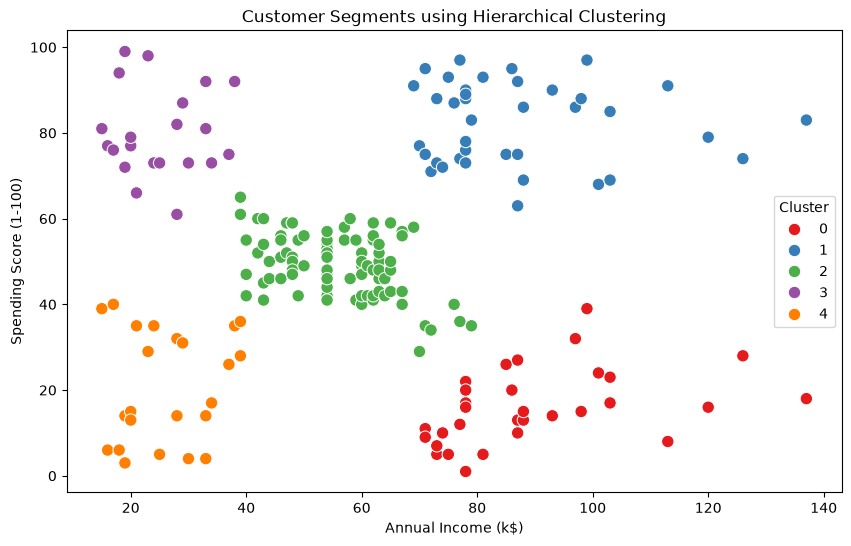

In [34]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Hierarchical_Cluster",
    palette="Set1",
    s=80
)

plt.title("Customer Segments using Hierarchical Clustering")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")

# Lưu biểu đồ
plt.savefig(
    "../results/figures/hierarchical_segments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 4.3.4. Model Evaluation – Silhouette Score

In [12]:
# Tính Silhouette Score
silhouette_hierarchical = calculate_silhouette(
    X_scaled,
    y_hierarchical
)

print(
    "Silhouette Score (Hierarchical):",
    silhouette_hierarchical
)

Silhouette Score (Hierarchical): 0.5538089226688662


## 5. COMPARISON AND EVALUATION

### 5.1. Comparison of Clustering Algorithms

Sau khi thực nghiệm ba thuật toán K-Means, DBSCAN và
Hierarchical Clustering, thu được kết quả như sau:

| Tiêu chí | K-Means | DBSCAN | Hierarchical |
|---|---:|---:|---:|
| Số cụm | 5 | 2 | 5 |
| Số điểm nhiễu | 0 | 8 | 0 |
| Silhouette Score | 0.5547 | 0.3876 | 0.5538 |

Nhận xét:

- K-Means đạt Silhouette Score cao nhất với 0.5547.
- Hierarchical đạt 0.5538, gần tương đương K-Means.
- DBSCAN đạt 0.3876 và phát hiện được 8 điểm nhiễu.

Lưu ý: Silhouette Score của DBSCAN được tính trên 192
điểm không nhiễu, trong khi hai thuật toán còn lại
được tính trên toàn bộ 200 điểm dữ liệu.

### 5.2. Final Model Selection

Dựa trên kết quả thực nghiệm, K-Means được lựa chọn
làm mô hình phù hợp nhất cho bài toán Customer
Segmentation trong phạm vi thử nghiệm này.

Lý do:
- Có Silhouette Score cao nhất.
- Phân chia được 5 nhóm khách hàng.
- Các cụm có đặc điểm thu nhập và điểm chi tiêu
  tương đối rõ ràng.
- Dễ triển khai và thuận tiện cho việc phân tích
  đặc điểm từng nhóm khách hàng.

Tuy nhiên, Hierarchical Clustering cũng cho kết quả
rất gần với K-Means. DBSCAN vẫn có ưu điểm riêng
trong việc phát hiện các điểm nhiễu.

In [35]:
# Phân tích đặc điểm trung bình của từng cụm
cluster_analysis = df.groupby("Cluster").agg({
    "Age": "mean",
    "Annual Income (k$)": "mean",
    "Spending Score (1-100)": "mean",
    "CustomerID": "count"
}).round(2)

# Đổi tên cột
cluster_analysis.rename(
    columns={"CustomerID": "Customer Count"},
    inplace=True
)

# Hiển thị kết quả
print(cluster_analysis)

# Lưu bảng kết quả
cluster_analysis.to_csv(
    "../results/tables/kmeans_cluster_analysis.csv",
    encoding="utf-8-sig"
)

           Age  Annual Income (k$)  Spending Score (1-100)  Customer Count
Cluster                                                                   
0        42.72               55.30                   49.52              81
1        32.69               86.54                   82.13              39
2        25.27               25.73                   79.36              22
3        41.11               88.20                   17.11              35
4        45.22               26.30                   20.91              23


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_15844\4091515827.py:10: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  cluster_analysis.rename(


In [36]:
# Hiển thị bảng phân tích cụm K-Means
display(cluster_analysis)

,Age,Annual Income (k$),Spending Score (1-100),Customer Count
Cluster,,,,
0,42.72,55.30,49.52,81
1,32.69,86.54,82.13,39
2,25.27,25.73,79.36,22
3,41.11,88.20,17.11,35
4,45.22,26.30,20.91,23


### 4.1.6. Customer Segment Analysis – Phân tích phân khúc khách hàng

Sau khi phân cụm bằng K-Means với K = 5, tiến hành
thống kê độ tuổi, thu nhập và điểm chi tiêu trung bình
của từng nhóm khách hàng.

Kết quả cho thấy 5 nhóm có những đặc điểm khác nhau:

- Cluster 0 – Average Customers:
  Nhóm khách hàng có thu nhập và điểm chi tiêu trung bình.
  Đây là nhóm đông nhất với 81 khách hàng.

- Cluster 1 – Premium Customers:
  Nhóm khách hàng có thu nhập cao và điểm chi tiêu cao.
  Có thể xem đây là nhóm khách hàng tiềm năng cho các
  sản phẩm và dịch vụ cao cấp.

- Cluster 2 – Young High-Spending Customers:
  Nhóm khách hàng trẻ, thu nhập thấp nhưng có điểm
  chi tiêu cao.

- Cluster 3 – Careful High-Income Customers:
  Nhóm khách hàng có thu nhập cao nhưng điểm chi tiêu thấp.
  Doanh nghiệp có thể tìm hiểu thêm nhu cầu của nhóm này
  để xây dựng chương trình tiếp thị phù hợp.

- Cluster 4 – Low-Income Low-Spending Customers:
  Nhóm khách hàng có thu nhập và điểm chi tiêu thấp.
  Có thể tập trung vào các sản phẩm có mức giá hợp lý.

Nhìn chung, K-Means đã hỗ trợ nhận diện các nhóm khách hàng
có đặc điểm và hành vi chi tiêu khác nhau. Kết quả này
có thể được sử dụng làm cơ sở để doanh nghiệp xây dựng
các chiến lược tiếp thị phù hợp với từng phân khúc.

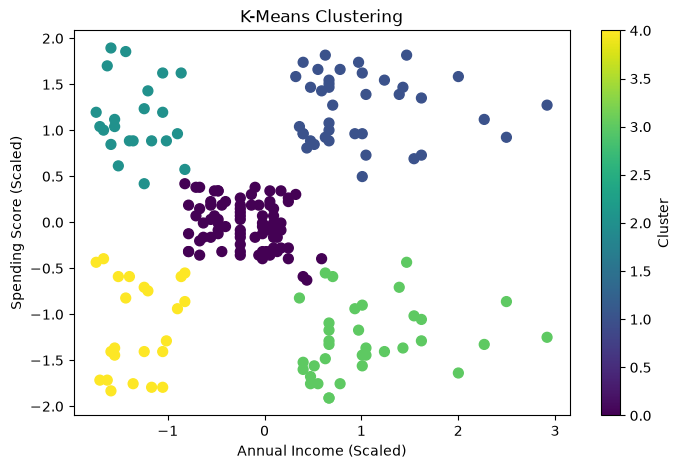

In [16]:
# Vẽ và lưu biểu đồ K-Means
plot_clusters(
    X_scaled,
    y_kmeans,
    "K-Means Clustering",
    save_path="../results/figures/kmeans_clustering.png"
)

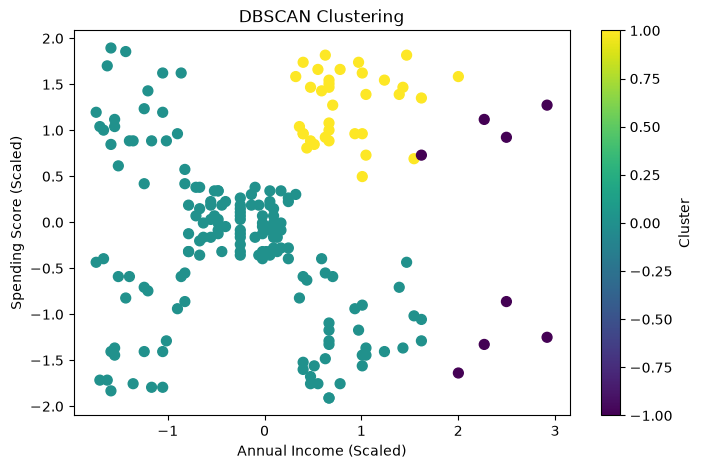

In [17]:
# Vẽ và lưu biểu đồ DBSCAN
plot_clusters(
    X_scaled,
    y_dbscan,
    "DBSCAN Clustering",
    save_path="../results/figures/dbscan_clustering.png"
)

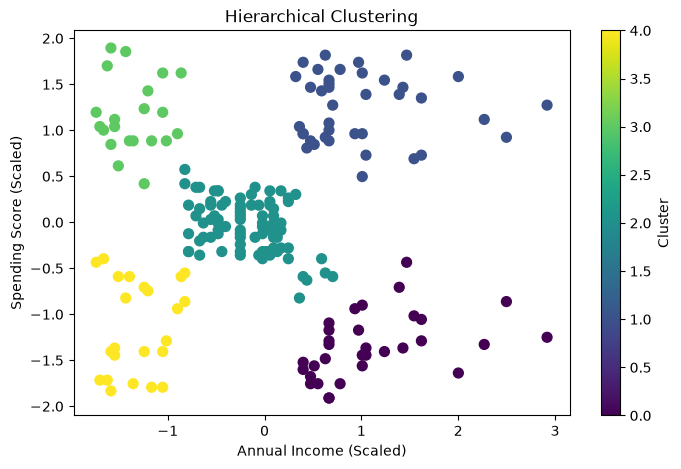

In [18]:
# Vẽ và lưu biểu đồ Hierarchical
plot_clusters(
    X_scaled,
    y_hierarchical,
    "Hierarchical Clustering",
    save_path="../results/figures/hierarchical_clustering.png"
)

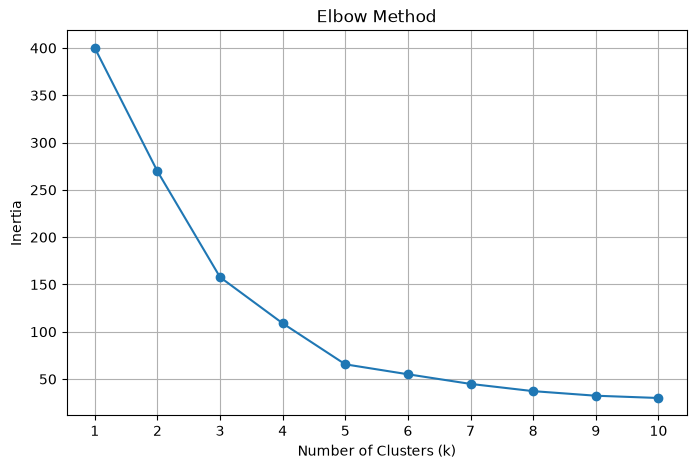

In [38]:
plot_elbow(
    inertia_values,
    save_path="../results/figures/elbow_method.png"
)

In [40]:
import joblib
from pathlib import Path

# Tạo thư mục models nếu chưa tồn tại
Path("../models").mkdir(parents=True, exist_ok=True)

print("Đã chuẩn bị thư mục lưu mô hình!")

Đã chuẩn bị thư mục lưu mô hình!


In [41]:
# Lưu mô hình K-Means
joblib.dump(
    kmeans,
    "../models/kmeans_model.pkl"
)

print("Đã lưu mô hình K-Means!")

Đã lưu mô hình K-Means!


In [42]:
# Lưu mô hình DBSCAN
joblib.dump(
    dbscan,
    "../models/dbscan_model.pkl"
)

print("Đã lưu mô hình DBSCAN!")

Đã lưu mô hình DBSCAN!


In [43]:
# Lưu mô hình Hierarchical
joblib.dump(
    hierarchical,
    "../models/hierarchical_model.pkl"
)

print("Đã lưu mô hình Hierarchical!")

Đã lưu mô hình Hierarchical!


In [44]:
# Lưu StandardScaler
joblib.dump(
    scaler,
    "../models/scaler.pkl"
)

print("Đã lưu StandardScaler!")

Đã lưu StandardScaler!


In [45]:
# Tổng hợp kết quả phân cụm của 3 thuật toán
clustering_results = df[[
    "CustomerID",
    "Gender",
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)",
    "Cluster",
    "DBSCAN_Cluster",
    "Hierarchical_Cluster"
]].copy()

# Lưu bảng kết quả
clustering_results.to_csv(
    "../results/tables/customer_clustering_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu kết quả phân cụm của 200 khách hàng!")

Đã lưu kết quả phân cụm của 200 khách hàng!


In [46]:
# Tổng hợp Silhouette Score của 3 thuật toán
evaluation_results = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "DBSCAN",
        "Hierarchical"
    ],
    "Silhouette Score": [
        silhouette_avg,
        silhouette_dbscan,
        silhouette_hierarchical
    ]
}).round(4)

# Hiển thị bảng
display(evaluation_results)

# Lưu bảng
evaluation_results.to_csv(
    "../results/tables/clustering_evaluation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu bảng đánh giá các mô hình!")

,Algorithm,Silhouette Score
0,K-Means,0.5547
1,DBSCAN,0.3876
2,Hierarchical,0.5538


Đã lưu bảng đánh giá các mô hình!


In [47]:
# Kiểm tra khả năng tải lại các mô hình
kmeans_loaded = joblib.load("../models/kmeans_model.pkl")
dbscan_loaded = joblib.load("../models/dbscan_model.pkl")
hierarchical_loaded = joblib.load("../models/hierarchical_model.pkl")
scaler_loaded = joblib.load("../models/scaler.pkl")

print("Đã tải lại thành công tất cả mô hình và Scaler!")

Đã tải lại thành công tất cả mô hình và Scaler!
